# 02.04. IPCA — Análise por Subitens



## Parte 0 — Granularidade • Impacto • Difusão • Concentração • Hierarquia

Este notebook representa o nível mais granular da decomposição
do IPCA utilizada neste projeto.

A progressão construída até aqui é:

* 02.ipca $\to\qquad$ IPCA geral
* 02.01.grupos $\to\qquad$ grandes componentes
* 02.02.subgrupos $\to\qquad$ componentes intermediários
* 02.03.itens $\to\qquad$ categorias específicas
* 02.04.subitens $\to\qquad$ produtos e serviços detalhados


O notebook assume que:

- os pipelines já foram executados;
- `bcb.ipca_subitens` está atualizada;
- `bcb.ipca_itens` está atualizada;
- `bcb.ipca_subgrupos` está atualizada;
- `bcb.ipca_grupos` está atualizada;
- a auditoria dos dados foi concluída.

Este notebook NÃO executa pipelines e NÃO altera o banco de dados.



## Objetivos

1. Entender o nível de subitem na hierarquia do IPCA.
2. Relacionar cada subitem ao item, subgrupo e grupo correspondentes.
3. Identificar produtos e serviços com movimentos extremos.
4. Calcular contribuição e impacto.
5. Identificar as principais pressões sobre a inflação.
6. Medir a difusão da inflação entre subitens.
7. Medir a concentração das pressões.
8. Analisar componentes específicos dentro de um item.
9. Verificar a consistência entre subitens e itens.
10. Preparar indicadores agregados para futura modelagem.

---

### 1. Hierarquia do IPCA

Neste projeto utilizamos:

```text
grupo      -> código de 1 dígito
subgrupo   -> código de 2 dígitos
item       -> código de 4 dígitos
subitem    -> código de 7 dígitos
```

Portanto:

```text
grupo
  |
  +-- subgrupo
         |
         +-- item
                |
                +-- subitem
                +-- subitem
                +-- subitem
```

Para um código de subitem com 7 dígitos:

- primeiro dígito identifica o grupo;
- dois primeiros identificam o subgrupo;
- quatro primeiros identificam o item;
- sete dígitos identificam o subitem.

### 2. O que representa um subitem?

O subitem representa o nível mais detalhado da estrutura analisada.

Exemplos típicos incluem produtos e serviços específicos.

Neste nível podemos investigar:

- choques específicos;
- alimentos;
- combustíveis;
- serviços;
- tarifas;
- produtos administrados;
- componentes com alta volatilidade.

Mas a maior granularidade produz também um desafio:

```text
    mais detalhe
        |
        v
  mais componentes
        |
        v
maior dimensionalidade
```

Por isso, o foco deixa de ser visualizar todas as séries
individualmente.

### 3. Estrutura matemática

Seja $\pi_{i,t}$ a variação mensal do subitem $i$ no período $t$.

Seja $w_{i,t}$ seu peso publicado.

A contribuição aproximada é:

$$
C_{i,t}=\pi_{i,t}\frac{w_{i,t}}{100}
$$

A contribuição preserva a direção do efeito.

Para medir a magnitude da pressão utilizamos:

$$
I_{i,t}=\left|C_{i,t}\right|
$$

Portanto:

* indice $\to\qquad$ movimento dos preços
* peso $\to\qquad$ importância relativa
* contribuicao $\to\qquad$ efeito com direção
* impacto $\to\qquad$ magnitude da pressão


### 4. Configuração do ambiente

In [69]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /home/moacir/projects/ml/analytics/inflation


### 5. Importações

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.patches import Patch

from src.database.connection import engine

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 250)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", "{:.4f}".format)

### 6. Carregar subitens do PostgreSQL

In [71]:
subitens = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_subitens
    ORDER BY date, categoria;
    """,
    engine,
)

#### 6.1 Preparar dados

In [72]:
subitens["date"] = pd.to_datetime(
    subitens["date"]
)

subitens["categoria"] = (
    subitens["categoria"]
    .astype(str)
)

subitens = (
    subitens
    .sort_values(
        ["date", "categoria"]
    )
    .reset_index(drop=True)
)

#### 6.2 Identificar níveis hierárquicos

In [73]:
subitens["grupo_codigo"] = (
    subitens["categoria"]
    .str[:1]
)

subitens["subgrupo_codigo"] = (
    subitens["categoria"]
    .str[:2]
)

subitens["item_codigo"] = (
    subitens["categoria"]
    .str[:4]
)

#### 6.3 Contribuição e impacto

In [74]:
subitens["contribuicao"] = (
    subitens["indice"]
    * subitens["peso"]
    / 100
)

subitens["impacto"] = (
    subitens["contribuicao"]
    .abs()
)

#### 6.4 Direção

In [75]:
subitens["direcao"] = np.select(
    [
        subitens["contribuicao"] > 0,
        subitens["contribuicao"] < 0,
    ],
    [
        "positiva",
        "negativa",
    ],
    default="neutra",
)

subitens.head(10)

,date,categoria,categoria_nome,indice,peso,grupo_codigo,subgrupo_codigo,item_codigo,contribuicao,impacto,direcao
0,2020-01-01,1101002,Arroz,1.3100,0.4753,1,11,1101,0.0062,0.0062,positiva
1,2020-01-01,1101051,Feijão - mulatinho,4.5000,0.0116,1,11,1101,0.0005,0.0005,positiva
2,2020-01-01,1101052,Feijão - preto,-2.6800,0.0486,1,11,1101,-0.0013,0.0013,negativa
3,2020-01-01,1101053,Feijão - macáçar (fradinho),5.3900,0.0121,1,11,1101,0.0007,0.0007,positiva
4,2020-01-01,1101073,Feijão - carioca (rajado),-0.7000,0.1350,1,11,1101,-0.0009,0.0009,negativa
5,2020-01-01,1101079,Milho (em grão),0.2000,0.0100,1,11,1101,0.0000,0.0000,positiva
6,2020-01-01,1102001,Farinha de arroz,1.2500,0.0028,1,11,1102,0.0000,0.0000,positiva
7,2020-01-01,1102006,Macarrão,-0.1800,0.1467,1,11,1102,-0.0003,0.0003,negativa
8,2020-01-01,1102008,Fubá de milho,0.4300,0.0079,1,11,1102,0.0000,0.0000,positiva
9,2020-01-01,1102010,Flocos de milho,-0.0300,0.0102,1,11,1102,-0.0000,0.0000,negativa


### 7. Carregar referências hierárquicas

In [76]:
grupos_ref = pd.read_sql(
    """
    SELECT DISTINCT
        categoria,
        categoria_nome
    FROM bcb.ipca_grupos
    ORDER BY categoria;
    """,
    engine,
)

subgrupos_ref = pd.read_sql(
    """
    SELECT DISTINCT
        categoria,
        categoria_nome
    FROM bcb.ipca_subgrupos
    ORDER BY categoria;
    """,
    engine,
)

itens_ref = pd.read_sql(
    """
    SELECT DISTINCT
        categoria,
        categoria_nome
    FROM bcb.ipca_itens
    ORDER BY categoria;
    """,
    engine,
)

#### 7.1 Preparar referências

In [77]:
grupos_ref["categoria"] = (
    grupos_ref["categoria"]
    .astype(str)
)

subgrupos_ref["categoria"] = (
    subgrupos_ref["categoria"]
    .astype(str)
)

itens_ref["categoria"] = (
    itens_ref["categoria"]
    .astype(str)
)

grupos_ref = grupos_ref.rename(
    columns={
        "categoria": "grupo_codigo",
        "categoria_nome": "grupo_nome",
    }
)

subgrupos_ref = subgrupos_ref.rename(
    columns={
        "categoria": "subgrupo_codigo",
        "categoria_nome": "subgrupo_nome",
    }
)

itens_ref = itens_ref.rename(
    columns={
        "categoria": "item_codigo",
        "categoria_nome": "item_nome",
    }
)

#### 7.2 Associar toda a hierarquia

In [78]:
subitens = (
    subitens
    .merge(
        grupos_ref,
        on="grupo_codigo",
        how="left",
        validate="many_to_one",
    )
    .merge(
        subgrupos_ref,
        on="subgrupo_codigo",
        how="left",
        validate="many_to_one",
    )
    .merge(
        itens_ref,
        on="item_codigo",
        how="left",
        validate="many_to_one",
    )
)

subitens[
    [
        "grupo_codigo",
        "grupo_nome",
        "subgrupo_codigo",
        "subgrupo_nome",
        "item_codigo",
        "item_nome",
        "categoria",
        "categoria_nome",
    ]
].drop_duplicates().head(20)

,grupo_codigo,grupo_nome,subgrupo_codigo,subgrupo_nome,item_codigo,item_nome,categoria,categoria_nome
0,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101002,Arroz
1,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101051,Feijão - mulatinho
2,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101052,Feijão - preto
3,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101053,Feijão - macáçar (fradinho)
4,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101073,Feijão - carioca (rajado)
5,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101079,Milho (em grão)
6,1,Alimentação e bebidas,11,Alimentação no domicílio,1102,"Farinhas, féculas e massas",1102001,Farinha de arroz
7,1,Alimentação e bebidas,11,Alimentação no domicílio,1102,"Farinhas, féculas e massas",1102006,Macarrão
8,1,Alimentação e bebidas,11,Alimentação no domicílio,1102,"Farinhas, féculas e massas",1102008,Fubá de milho
9,1,Alimentação e bebidas,11,Alimentação no domicílio,1102,"Farinhas, féculas e massas",1102010,Flocos de milho


### 8. Cobertura histórica

In [119]:
resumo = pd.DataFrame(
    [
        {
            "inicio": subitens["date"].min(),
            "fim": subitens["date"].max(),
            "observacoes": len(subitens),
            "subitens": subitens["categoria"].nunique(),
            "itens": subitens["item_codigo"].nunique(),
            "subgrupos": subitens["subgrupo_codigo"].nunique(),
            "grupos": subitens["grupo_codigo"].nunique(),
        }
    ]
)

resumo

,inicio,fim,observacoes,subitens,itens,subgrupos,grupos
0,2020-01-01,2026-08-01,30160,377,51,19,9


### 9. Catálogo hierárquico

No nível de subitens, o catálogo torna-se especialmente importante
para navegar pela estrutura.

In [122]:
catalogo = (
    subitens[
        [
            "grupo_codigo",
            "grupo_nome",
            "subgrupo_codigo",
            "subgrupo_nome",
            "item_codigo",
            "item_nome",
            "categoria",
            "categoria_nome",
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "grupo_codigo",
            "subgrupo_codigo",
            "item_codigo",
            "categoria",
        ]
    )
    .reset_index(drop=True)
)

catalogo.head(20)

,grupo_codigo,grupo_nome,subgrupo_codigo,subgrupo_nome,item_codigo,item_nome,categoria,categoria_nome
0,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101002,Arroz
1,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101051,Feijão - mulatinho
2,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101052,Feijão - preto
3,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101053,Feijão - macáçar (fradinho)
4,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101073,Feijão - carioca (rajado)
5,1,Alimentação e bebidas,11,Alimentação no domicílio,1101,"Cereais, leguminosas e oleaginosas",1101079,Milho (em grão)
6,1,Alimentação e bebidas,11,Alimentação no domicílio,1102,"Farinhas, féculas e massas",1102001,Farinha de arroz
7,1,Alimentação e bebidas,11,Alimentação no domicílio,1102,"Farinhas, féculas e massas",1102006,Macarrão
8,1,Alimentação e bebidas,11,Alimentação no domicílio,1102,"Farinhas, féculas e massas",1102008,Fubá de milho
9,1,Alimentação e bebidas,11,Alimentação no domicílio,1102,"Farinhas, féculas e massas",1102010,Flocos de milho


### 10. Quantidade de subitens por item

In [124]:
quantidade_por_item = (
    catalogo
    .groupby(
        [
            "grupo_nome",
            "subgrupo_nome",
            "item_codigo",
            "item_nome",
        ]
    )
    .size()
    .rename("subitens")
    .reset_index()
    .sort_values(
        "subitens",
        ascending=False,
    )
)

quantidade_por_item.head(20)

,grupo_nome,subgrupo_nome,item_codigo,item_nome,subitens
8,Alimentação e bebidas,Alimentação no domicílio,1108,Pescados,22
6,Alimentação e bebidas,Alimentação no domicílio,1106,Frutas,21
7,Alimentação e bebidas,Alimentação no domicílio,1107,Carnes,18
37,Saúde e cuidados pessoais,Produtos farmacêuticos e óticos,6101,Produtos farmacêuticos,14
43,Transportes,Transportes,5102,Veículo próprio,14
34,Habitação,Encargos e manutenção,2103,Reparos,13
24,Despesas pessoais,Recreação e fumo,7201,Recreação,13
36,Saúde e cuidados pessoais,Cuidados pessoais,6301,Higiene pessoal,12
16,Alimentação e bebidas,Alimentação no domicílio,1116,Sal e condimentos,11
35,Habitação,Encargos e manutenção,2104,Artigos de limpeza,11


---

## PARTE I — ÚLTIMO MÊS



### 11. Último mês disponível

In [125]:
ultimo_mes = subitens["date"].max()

subitens_ultimo = (
    subitens[
        subitens["date"] == ultimo_mes
    ]
    .copy()
)

print(
    "Último mês disponível:",
    ultimo_mes.strftime("%Y-%m"),
)

print(
    "Subitens disponíveis:",
    len(subitens_ultimo),
)

Último mês disponível: 2026-08
Subitens disponíveis: 377


### 12. Subitens com maior peso

A maior granularidade permite observar quais produtos e serviços
específicos possuem maior relevância relativa na estrutura do índice.

In [83]:
subitens_ultimo[
    [
        "grupo_nome",
        "subgrupo_nome",
        "item_nome",
        "categoria_nome",
        "peso",
    ]
].sort_values(
    "peso",
    ascending=False,
).head(30)

,grupo_nome,subgrupo_nome,item_nome,categoria_nome,peso
30069,Transportes,Transportes,Combustíveis (veículos),Gasolina,5.1423
29982,Habitação,Combustíveis e energia,Energia elétrica residencial,Energia elétrica residencial,4.2960
30096,Saúde e cuidados pessoais,Serviços de saúde,Plano de saúde,Plano de saúde,4.1405
29951,Habitação,Encargos e manutenção,Aluguel e taxas,Aluguel residencial,3.6376
29942,Alimentação e bebidas,Alimentação fora do domicílio,Alimentação fora do domicílio,Refeição,3.6158
30055,Transportes,Transportes,Veículo próprio,Automóvel novo,2.9542
30111,Despesas pessoais,Serviços pessoais,Serviços pessoais,Empregado doméstico,2.7469
30056,Transportes,Transportes,Veículo próprio,Emplacamento e licença,2.5765
29952,Habitação,Encargos e manutenção,Aluguel e taxas,Condomínio,2.2238
29943,Alimentação e bebidas,Alimentação fora do domicílio,Alimentação fora do domicílio,Lanche,1.9387


### 13. Maiores variações positivas

Esta análise considera apenas $\pi_{i,t}$.

Uma variação muito alta não significa necessariamente grande impacto,
pois o peso do componente pode ser pequeno.

In [84]:
subitens_ultimo[
    [
        "grupo_nome",
        "subgrupo_nome",
        "item_nome",
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
        "impacto",
    ]
].nlargest(
    25,
    "indice",
)

,grupo_nome,subgrupo_nome,item_nome,categoria_nome,indice,peso,contribuicao,impacto
29830,Alimentação e bebidas,Alimentação no domicílio,Frutas,Limão,53.4000,0.0197,0.0105,0.0105
30132,Despesas pessoais,Recreação e fumo,Fumo,Cigarro,19.5900,0.5785,0.1133,0.1133
29834,Alimentação e bebidas,Alimentação no domicílio,Frutas,Maracujá,19.2200,0.0084,0.0016,0.0016
29803,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Pimentão,6.2400,0.0237,0.0015,0.0015
29869,Alimentação e bebidas,Alimentação no domicílio,Pescados,Peixe - serra,5.7600,0.0009,0.0001,0.0001
29845,Alimentação e bebidas,Alimentação no domicílio,Carnes,Carne de carneiro,3.7700,0.0022,0.0001,0.0001
29858,Alimentação e bebidas,Alimentação no domicílio,Carnes,Capa de filé,3.6600,0.0347,0.0013,0.0013
29873,Alimentação e bebidas,Alimentação no domicílio,Pescados,Peixe - palombeta,3.1300,0.0006,0.0000,0.0000
29822,Alimentação e bebidas,Alimentação no domicílio,Frutas,Banana-da-terra,2.9300,0.0184,0.0005,0.0005
29875,Alimentação e bebidas,Alimentação no domicílio,Pescados,Peixe - salmão,2.9000,0.0138,0.0004,0.0004


### 14. Maiores variações negativas

In [85]:
subitens_ultimo[
    [
        "grupo_nome",
        "subgrupo_nome",
        "item_nome",
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
        "impacto",
    ]
].nsmallest(
    25,
    "indice",
)

,grupo_nome,subgrupo_nome,item_nome,categoria_nome,indice,peso,contribuicao,impacto
29798,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Batata-inglesa,-19.8900,0.2295,-0.0456,0.0456
30050,Transportes,Transportes,Transporte público,Passagem aérea,-13.1700,0.8159,-0.1075,0.1075
29802,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Pepino,-12.3900,0.0040,-0.0005,0.0005
29806,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Cenoura,-11.2200,0.0838,-0.0094,0.0094
29805,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Cebola,-11.0700,0.1831,-0.0203,0.0203
29804,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Tomate,-10.9400,0.2458,-0.0269,0.0269
29913,Alimentação e bebidas,Alimentação no domicílio,Bebidas e infusões,Açaí (emulsão),-10.4900,0.0663,-0.0070,0.0070
29841,Alimentação e bebidas,Alimentação no domicílio,Frutas,Morango,-9.9400,0.0170,-0.0017,0.0017
29818,Alimentação e bebidas,Alimentação no domicílio,Hortaliças e verduras,Couve-flor,-9.6300,0.0033,-0.0003,0.0003
29801,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Abobrinha,-8.8800,0.0090,-0.0008,0.0008


### 15. Principais pressões

Quando falamos em pressão, utilizamos preferencialmente o impacto:

$$
I_{i,t}=|C_{i,t}|
$$

Assim, contribuições positivas e negativas competem no mesmo ranking
pela magnitude.

In [127]:
ranking_impacto = (
    subitens_ultimo[
        [
            "grupo_nome",
            "subgrupo_nome",
            "item_nome",
            "categoria_nome",
            "indice",
            "peso",
            "contribuicao",
            "impacto",
            "direcao",
        ]
    ]
    .sort_values(
        "impacto",
        ascending=False,
    )
    .reset_index(drop=True)
)

ranking_impacto.head(20)

,grupo_nome,subgrupo_nome,item_nome,categoria_nome,indice,peso,contribuicao,impacto,direcao
0,Habitação,Combustíveis e energia,Energia elétrica residencial,Energia elétrica residencial,-7.6300,4.2960,-0.3278,0.3278,negativa
1,Despesas pessoais,Recreação e fumo,Fumo,Cigarro,19.5900,0.5785,0.1133,0.1133,positiva
2,Transportes,Transportes,Transporte público,Passagem aérea,-13.1700,0.8159,-0.1075,0.1075,negativa
3,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Batata-inglesa,-19.8900,0.2295,-0.0456,0.0456,negativa
4,Transportes,Transportes,Combustíveis (veículos),Gasolina,-0.5900,5.1423,-0.0303,0.0303,negativa
5,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Tomate,-10.9400,0.2458,-0.0269,0.0269,negativa
6,Transportes,Transportes,Veículo próprio,Conserto de automóvel,1.3500,1.8417,0.0249,0.0249,positiva
7,Transportes,Transportes,Combustíveis (veículos),Etanol,-3.9500,0.6201,-0.0245,0.0245,negativa
8,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Cebola,-11.0700,0.1831,-0.0203,0.0203,negativa
9,Saúde e cuidados pessoais,Serviços de saúde,Plano de saúde,Plano de saúde,0.4200,4.1405,0.0174,0.0174,positiva


### 16. Gráfico das principais pressões

O comprimento da barra representa $I_{i,t}$.

A cor recupera o sinal de $C_{i,t}$:

- vermelho -> contribuição positiva;
- azul -> contribuição negativa.

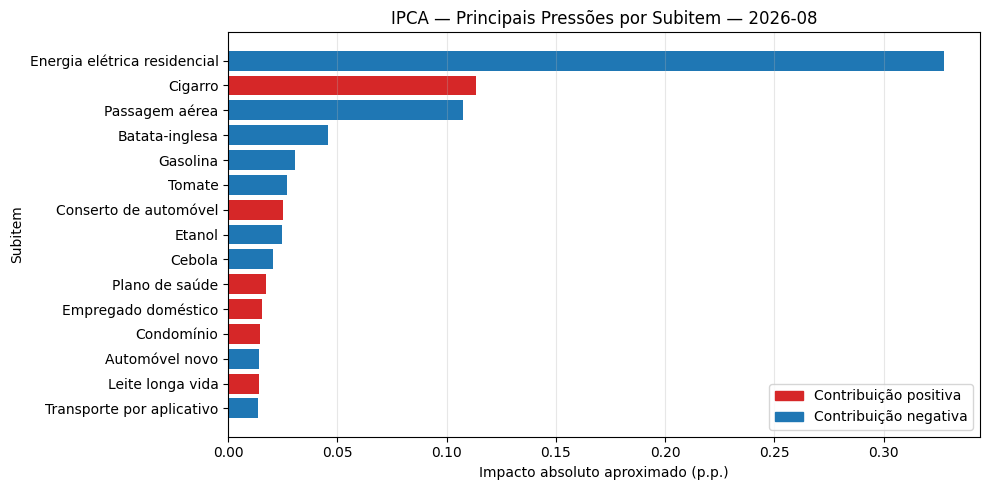

In [130]:
top_impacto = (
    ranking_impacto
    .head(15)
    .sort_values("impacto")
)

cores = np.where(
    top_impacto["contribuicao"] >= 0,
    "tab:red",
    "tab:blue",
)

plt.figure(figsize=(10, 5))

plt.barh(
    top_impacto["categoria_nome"],
    top_impacto["impacto"],
    color=cores,
)

plt.title(
    f"IPCA — Principais Pressões por Subitem — {ultimo_mes:%Y-%m}"
)

plt.xlabel("Impacto absoluto aproximado (p.p.)")
plt.ylabel("Subitem")

plt.grid(
    True,
    axis="x",
    alpha=0.3,
)

legenda = [
    Patch(
        color="tab:red",
        label="Contribuição positiva",
    ),
    Patch(
        color="tab:blue",
        label="Contribuição negativa",
    ),
]

plt.legend(
    handles=legenda,
    loc="lower right",
)

plt.tight_layout()
plt.show()

### 17. Direção das principais pressões

O impacto mostra magnitude.

A contribuição recupera a direção:

$$
C_{i,t}=\pi_{i,t}\frac{w_{i,t}}{100}
$$

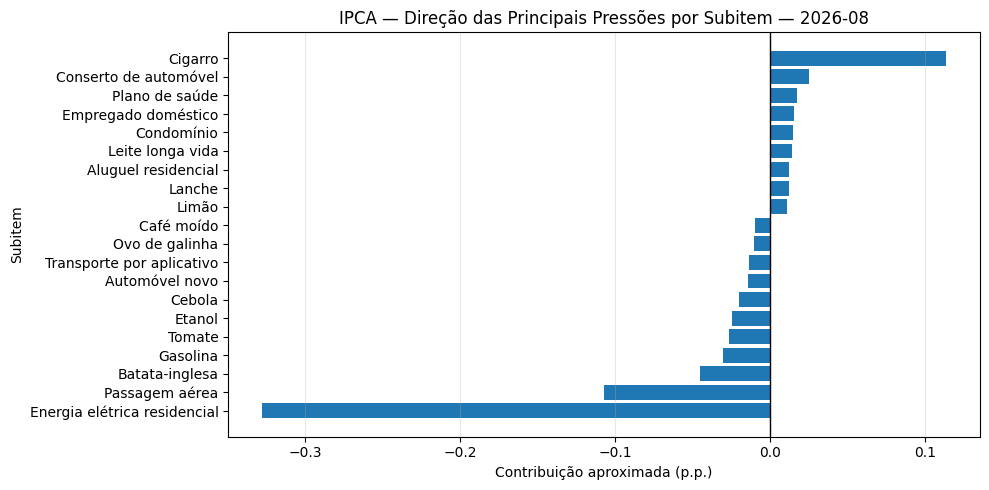

In [132]:
top_pressao_direcao = (
    subitens_ultimo
    .sort_values(
        "impacto",
        ascending=False,
    )
    .head(20)
    .sort_values("contribuicao")
)

plt.figure(figsize=(10, 5))

plt.barh(
    top_pressao_direcao["categoria_nome"],
    top_pressao_direcao["contribuicao"],
)

plt.axvline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    f"IPCA — Direção das Principais Pressões por Subitem — {ultimo_mes:%Y-%m}"
)

plt.xlabel("Contribuição aproximada (p.p.)")
plt.ylabel("Subitem")

plt.grid(
    True,
    axis="x",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

---

## PARTE II — DISTRIBUIÇÃO DOS MOVIMENTOS



### 18. Distribuição das variações

Com centenas de componentes, a distribuição das variações passa a
fornecer uma visão mais adequada do conjunto que um gráfico com
centenas de séries.

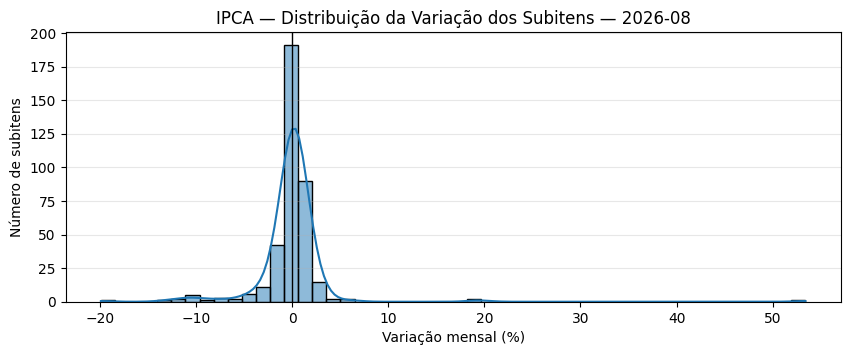

In [134]:
plt.figure(figsize=(10, 3.5))

sns.histplot(
    subitens_ultimo["indice"],
    bins=50,
    kde=True,
)

plt.axvline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    f"IPCA — Distribuição da Variação dos Subitens — {ultimo_mes:%Y-%m}"
)

plt.xlabel("Variação mensal (%)")
plt.ylabel("Número de subitens")

plt.grid(
    True,
    axis="y",
    alpha=0.3,
)

plt.show()

### 19. Estatísticas da distribuição

In [90]:
subitens_ultimo["indice"].describe()

count   377.0000
mean     -0.0433
std       3.9776
min     -19.8900
25%      -0.5100
50%       0.1300
75%       0.7300
max      53.4000
Name: indice, dtype: float64

### 20. Dispersão

A amplitude é definida por:

$$
A_t=\max_i(\pi_{i,t})-\min_i(\pi_{i,t})
$$

Como a amplitude é sensível a valores extremos, também calculamos
o intervalo interquartil:

$$
IQR_t=Q_{0.75,t}-Q_{0.25,t}
$$

In [135]:
q1 = (
    subitens_ultimo["indice"]
    .quantile(0.25)
)

q3 = (
    subitens_ultimo["indice"]
    .quantile(0.75)
)

dispersao_atual = pd.DataFrame(
    [
        {
            "media": subitens_ultimo["indice"].mean(),
            "mediana": subitens_ultimo["indice"].median(),
            "desvio_padrao": subitens_ultimo["indice"].std(),
            "q1": q1,
            "q3": q3,
            "iqr": q3 - q1,
            "minimo": subitens_ultimo["indice"].min(),
            "maximo": subitens_ultimo["indice"].max(),
            "amplitude": (
                subitens_ultimo["indice"].max()
                - subitens_ultimo["indice"].min()
            ),
        }
    ]
)

dispersao_atual

,media,mediana,desvio_padrao,q1,q3,iqr,minimo,maximo,amplitude
0,-0.0433,0.1300,3.9776,-0.5100,0.7300,1.2400,-19.8900,53.4000,73.2900


### 21. Valores extremos

Valores extremos de `indice` não devem ser interpretados isoladamente.

Devemos verificar simultaneamente:

```text
indice
peso
impacto
```

In [136]:
extremos_positivos = (
    subitens_ultimo
    .nlargest(
        10,
        "indice",
    )[
        [
            "grupo_nome",
            "subgrupo_nome",
            "item_nome",
            "categoria_nome",
            "indice",
            "peso",
            "contribuicao",
            "impacto",
        ]
    ]
)

extremos_positivos

,grupo_nome,subgrupo_nome,item_nome,categoria_nome,indice,peso,contribuicao,impacto
29830,Alimentação e bebidas,Alimentação no domicílio,Frutas,Limão,53.4000,0.0197,0.0105,0.0105
30132,Despesas pessoais,Recreação e fumo,Fumo,Cigarro,19.5900,0.5785,0.1133,0.1133
29834,Alimentação e bebidas,Alimentação no domicílio,Frutas,Maracujá,19.2200,0.0084,0.0016,0.0016
29803,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Pimentão,6.2400,0.0237,0.0015,0.0015
29869,Alimentação e bebidas,Alimentação no domicílio,Pescados,Peixe - serra,5.7600,0.0009,0.0001,0.0001
29845,Alimentação e bebidas,Alimentação no domicílio,Carnes,Carne de carneiro,3.7700,0.0022,0.0001,0.0001
29858,Alimentação e bebidas,Alimentação no domicílio,Carnes,Capa de filé,3.6600,0.0347,0.0013,0.0013
29873,Alimentação e bebidas,Alimentação no domicílio,Pescados,Peixe - palombeta,3.1300,0.0006,0.0000,0.0000
29822,Alimentação e bebidas,Alimentação no domicílio,Frutas,Banana-da-terra,2.9300,0.0184,0.0005,0.0005
29875,Alimentação e bebidas,Alimentação no domicílio,Pescados,Peixe - salmão,2.9000,0.0138,0.0004,0.0004


In [93]:
extremos_negativos = (
    subitens_ultimo
    .nsmallest(
        10,
        "indice",
    )[
        [
            "grupo_nome",
            "subgrupo_nome",
            "item_nome",
            "categoria_nome",
            "indice",
            "peso",
            "contribuicao",
            "impacto",
        ]
    ]
)

extremos_negativos

,grupo_nome,subgrupo_nome,item_nome,categoria_nome,indice,peso,contribuicao,impacto
29798,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Batata-inglesa,-19.8900,0.2295,-0.0456,0.0456
30050,Transportes,Transportes,Transporte público,Passagem aérea,-13.1700,0.8159,-0.1075,0.1075
29802,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Pepino,-12.3900,0.0040,-0.0005,0.0005
29806,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Cenoura,-11.2200,0.0838,-0.0094,0.0094
29805,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Cebola,-11.0700,0.1831,-0.0203,0.0203
29804,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Tomate,-10.9400,0.2458,-0.0269,0.0269
29913,Alimentação e bebidas,Alimentação no domicílio,Bebidas e infusões,Açaí (emulsão),-10.4900,0.0663,-0.0070,0.0070
29841,Alimentação e bebidas,Alimentação no domicílio,Frutas,Morango,-9.9400,0.0170,-0.0017,0.0017
29818,Alimentação e bebidas,Alimentação no domicílio,Hortaliças e verduras,Couve-flor,-9.6300,0.0033,-0.0003,0.0003
29801,Alimentação e bebidas,Alimentação no domicílio,"Tubérculos, raízes e legumes",Abobrinha,-8.8800,0.0090,-0.0008,0.0008


#### Interpretação

Um subitem pode apresentar uma variação extremamente elevada e,
ainda assim, produzir impacto pequeno sobre o IPCA.

Isso ocorre porque:

$$
I_{i,t}=\left|\pi_{i,t}\frac{w_{i,t}}{100}\right|
$$

Portanto, variação e relevância econômica não são equivalentes.

---

## PARTE III — DIFUSÃO



### 22. Definição

Seja $N_t$ o número de subitens observados no período $t$.

A difusão é:

$$
D_t=\frac{\sum_{i=1}^{N_t}\mathbf{1}\left(\pi_{i,t}>0\right)}{N_t}
$$

Portanto, $D_t$ representa a proporção de subitens com variação
positiva naquele mês.

A difusão NÃO considera peso ou magnitude.

### 23. Calcular difusão

In [137]:
difusao_subitens = (
    subitens
    .assign(
        positivo=(
            subitens["indice"] > 0
        )
    )
    .groupby("date")
    .agg(
        subitens=(
            "categoria",
            "count",
        ),
        positivos=(
            "positivo",
            "sum",
        ),
    )
)

difusao_subitens["difusao"] = (
    difusao_subitens["positivos"]
    / difusao_subitens["subitens"]
)

difusao_subitens.tail(12)

,subitens,positivos,difusao
date,,,
2025-09-01,377,197,0.5225
2025-10-01,377,197,0.5225
2025-11-01,377,210,0.5570
2025-12-01,377,228,0.6048
2026-01-01,377,241,0.6393
2026-02-01,377,231,0.6127
2026-03-01,377,254,0.6737
2026-04-01,377,246,0.6525
2026-05-01,377,245,0.6499


### 24. Difusão no último mês

In [138]:
difusao_atual = (
    difusao_subitens
    .loc[[ultimo_mes]]
    .copy()
)

difusao_atual["difusao_pct"] = (
    difusao_atual["difusao"]
    * 100
)

difusao_atual

,subitens,positivos,difusao,difusao_pct
date,,,,
2026-08-01,377,205,0.5438,54.3767


### 25. Evolução recente da difusão

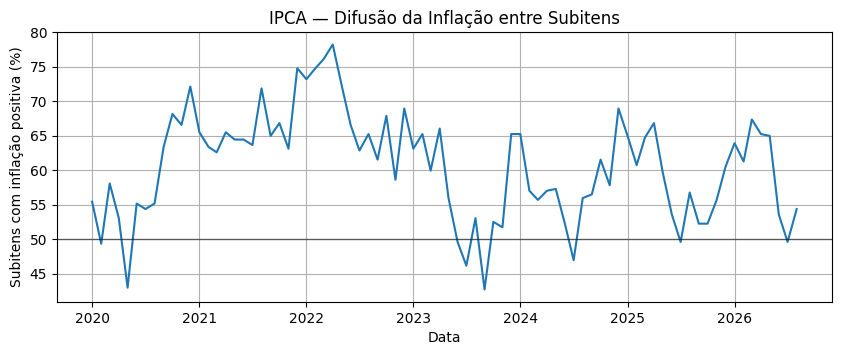

In [139]:
data_inicio_10a = (
    subitens["date"].max()
    - pd.DateOffset(years=10)
)

difusao_10a = (
    difusao_subitens[
        difusao_subitens.index
        >= data_inicio_10a
    ]
)

plt.figure(figsize=(10, 3.5))

plt.plot(
    difusao_10a.index,
    difusao_10a["difusao"] * 100,
)

plt.axhline(
    50,
    color="black",
    linewidth=1,
    alpha=0.5,
)

plt.title(
    "IPCA — Difusão da Inflação entre Subitens"
)

plt.xlabel("Data")
plt.ylabel("Subitens com inflação positiva (%)")

plt.grid(True)

plt.show()

### 26. Interpretação

A difusão permite distinguir:

```text
inflação disseminada
        vs.
inflação concentrada
```

Uma difusão de $80\%$, por exemplo, significa que 8 em cada 10
subitens observados apresentaram variação positiva.

Isso não significa que os componentes tenham a mesma importância
econômica.

---

## PARTE IV — CONCENTRAÇÃO DAS PRESSÕES



### 27. Impacto total

Definimos:

$$
I_t^{total}=\sum_{i=1}^{N_t} I_{i,t}
$$

Importante:

$$
I_t^{total} \neq IPCA_t
$$

pois os impactos removem os sinais das contribuições.

In [140]:
impacto_mensal = (
    subitens
    .groupby(
        "date",
        as_index=False,
    )["impacto"]
    .sum()
    .rename(
        columns={
            "impacto":
            "impacto_total"
        }
    )
)

impacto_mensal.tail(12)

,date,impacto_total
68,2025-09-01,1.1188
69,2025-10-01,0.6823
70,2025-11-01,0.8023
71,2025-12-01,0.9141
72,2026-01-01,1.1381
73,2026-02-01,1.1120
74,2026-03-01,1.1340
75,2026-04-01,1.1176
76,2026-05-01,1.0302
77,2026-06-01,0.6509


### 28. Concentração nos maiores impactos

Com muitos subitens, usar apenas os 5 maiores pode representar uma
parcela muito pequena da estrutura.

Por isso calcularemos:

- Top 5;
- Top 10;
- Top 20.

Para $k$ componentes:

$$
K_{k,t}=\frac{\sum_{i \in TopK_t} I_{i,t}}{\sum_i I_{i,t}}
$$

In [141]:
def concentracao_top_n(grupo, n):

    impactos = (
        grupo["impacto"]
        .sort_values(
            ascending=False
        )
    )

    total = impactos.sum()

    if total == 0:
        return 0.0

    return (
        impactos.head(n).sum()
        / total
    )

In [142]:
concentracao = pd.DataFrame(
    {
        "top5": (
            subitens
            .groupby("date")
            .apply(
                concentracao_top_n,
                n=5,
                include_groups=False,
            )
        ),
        "top10": (
            subitens
            .groupby("date")
            .apply(
                concentracao_top_n,
                n=10,
                include_groups=False,
            )
        ),
        "top20": (
            subitens
            .groupby("date")
            .apply(
                concentracao_top_n,
                n=20,
                include_groups=False,
            )
        ),
    }
)

concentracao.tail(12)

,top5,top10,top20
date,,,
2025-09-01,0.4867,0.5597,0.6671
2025-10-01,0.2953,0.4031,0.5695
2025-11-01,0.2831,0.4097,0.5516
2025-12-01,0.3319,0.4487,0.5881
2026-01-01,0.3515,0.5122,0.6632
2026-02-01,0.3202,0.4291,0.5670
2026-03-01,0.3804,0.4661,0.6123
2026-04-01,0.3392,0.4252,0.5575
2026-05-01,0.4069,0.5310,0.6337


### 29. Evolução da concentração

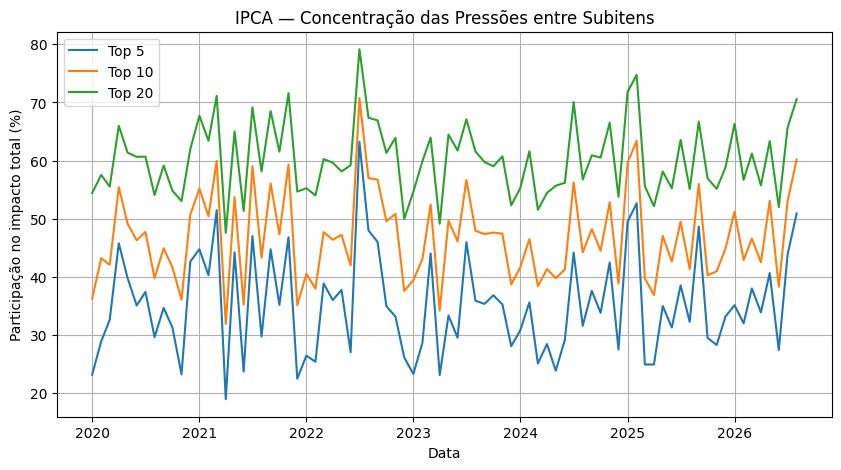

In [144]:
concentracao_10a = (
    concentracao[
        concentracao.index
        >= data_inicio_10a
    ]
)

plt.figure(figsize=(10, 5))

plt.plot(
    concentracao_10a.index,
    concentracao_10a["top5"] * 100,
    label="Top 5",
)

plt.plot(
    concentracao_10a.index,
    concentracao_10a["top10"] * 100,
    label="Top 10",
)

plt.plot(
    concentracao_10a.index,
    concentracao_10a["top20"] * 100,
    label="Top 20",
)

plt.title(
    "IPCA — Concentração das Pressões entre Subitens"
)

plt.xlabel("Data")
plt.ylabel("Participação no impacto total (%)")

plt.legend()
plt.grid(True)

plt.show()

### 30. Difusão versus concentração

As medidas capturam dimensões diferentes.

* difusão $\to\qquad$ quantos componentes estão aumentando?
* concentração $\to\qquad$ poucos componentes dominam as pressões?


Por exemplo:

* **Alta difusão + baixa concentração**  
Muitos preços subindo e impactos distribuídos.

* **Baixa difusão + alta concentração**  
Poucos componentes dominam os movimentos.

Essa distinção pode ser muito útil para caracterizar regimes
inflacionários.

---

## PARTE V — ANÁLISE DENTRO DE UM ITEM



### 31. Selecionar item

No nível de subitens, a análise individual deve ser feita dentro
do item-pai.

```text
selecionar item
      |
      v
analisar seus subitens
```

In [145]:
item_escolhido = (
    itens_ref
    .sort_values("item_codigo")
    .iloc[0]["item_nome"]
)

item_escolhido

'Cereais, leguminosas e oleaginosas'

O item pode ser definido explicitamente:

```python
item_escolhido = "Carnes"
```

In [146]:
subitens_item = (
    subitens[
        subitens["item_nome"]
        == item_escolhido
    ]
    .copy()
)

subitens_item[
    [
        "categoria",
        "categoria_nome",
    ]
].drop_duplicates()

,categoria,categoria_nome
0,1101002,Arroz
1,1101051,Feijão - mulatinho
2,1101052,Feijão - preto
3,1101053,Feijão - macáçar (fradinho)
4,1101073,Feijão - carioca (rajado)
5,1101079,Milho (em grão)


### 32. Subitens do item no último mês

In [103]:
subitens_item_ultimo = (
    subitens_item[
        subitens_item["date"]
        == ultimo_mes
    ]
    .sort_values(
        "impacto",
        ascending=False,
    )
)

subitens_item_ultimo[
    [
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
        "impacto",
        "direcao",
    ]
]

,categoria_nome,indice,peso,contribuicao,impacto,direcao
29787,Feijão - carioca (rajado),-4.8200,0.1440,-0.0069,0.0069,negativa
29783,Arroz,1.3400,0.5018,0.0067,0.0067,positiva
29785,Feijão - preto,-0.6300,0.0434,-0.0003,0.0003,negativa
29786,Feijão - macáçar (fradinho),-1.2000,0.0163,-0.0002,0.0002,negativa
29788,Milho (em grão),-1.0400,0.0125,-0.0001,0.0001,negativa
29784,Feijão - mulatinho,0.1100,0.0135,0.0000,0.0000,positiva


### 33. Pressões dentro do item

O comprimento da barra representa impacto.

A cor representa a direção da contribuição.

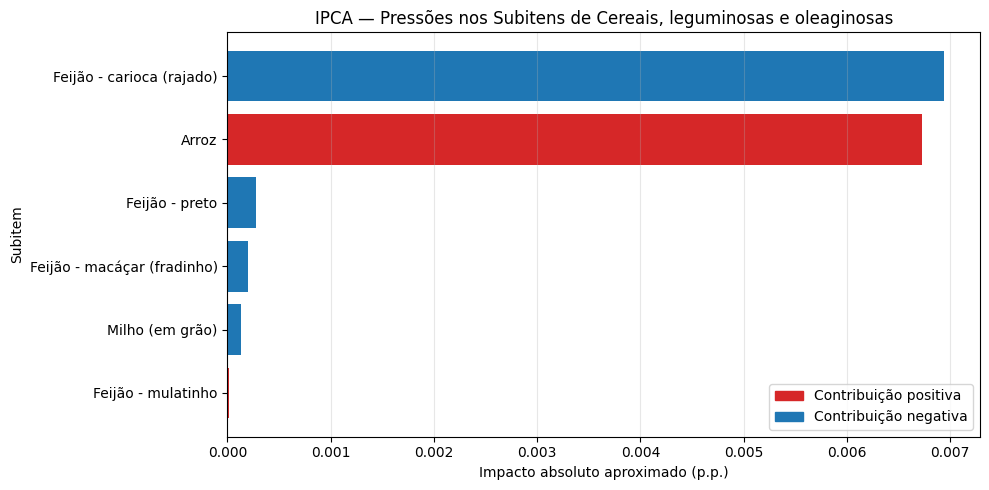

In [147]:
pressao_item = (
    subitens_item_ultimo
    .sort_values("impacto")
)

cores = np.where(
    pressao_item["contribuicao"] >= 0,
    "tab:red",
    "tab:blue",
)

plt.figure(
    figsize=(
        10,
        max(
            5,
            len(pressao_item) * 0.35,
        ),
    )
)

plt.barh(
    pressao_item["categoria_nome"],
    pressao_item["impacto"],
    color=cores,
)

plt.title(
    f"IPCA — Pressões nos Subitens de {item_escolhido}"
)

plt.xlabel("Impacto absoluto aproximado (p.p.)")
plt.ylabel("Subitem")

plt.grid(
    True,
    axis="x",
    alpha=0.3,
)

legenda = [
    Patch(
        color="tab:red",
        label="Contribuição positiva",
    ),
    Patch(
        color="tab:blue",
        label="Contribuição negativa",
    ),
]

plt.legend(
    handles=legenda,
    loc="lower right",
)

plt.tight_layout()
plt.show()

### 34. Direção das pressões dentro do item

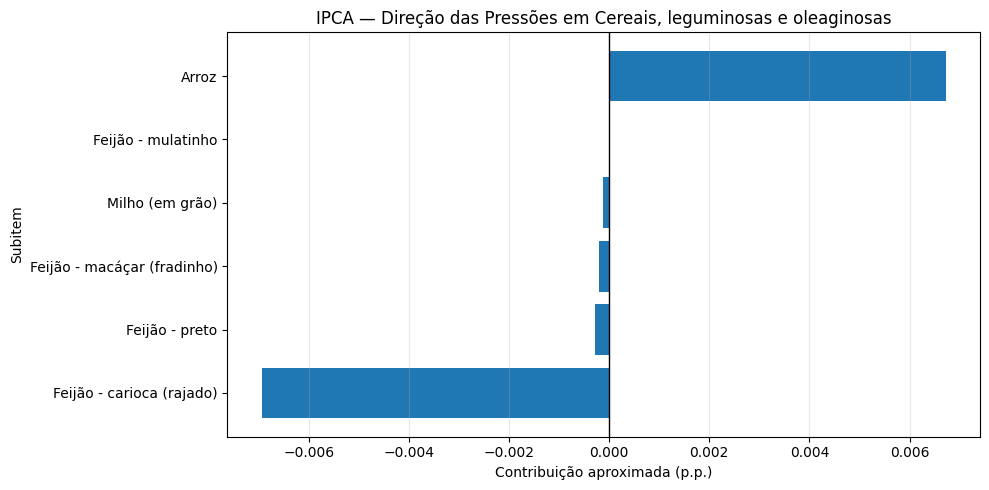

In [148]:
direcao_item = (
    subitens_item_ultimo
    .sort_values("contribuicao")
)

plt.figure(
    figsize=(
        10,
        max(
            5,
            len(direcao_item) * 0.35,
        ),
    )
)

plt.barh(
    direcao_item["categoria_nome"],
    direcao_item["contribuicao"],
)

plt.axvline(
    0,
    color="black",
    linewidth=1,
)

plt.title(
    f"IPCA — Direção das Pressões em {item_escolhido}"
)

plt.xlabel("Contribuição aproximada (p.p.)")
plt.ylabel("Subitem")

plt.grid(
    True,
    axis="x",
    alpha=0.3,
)

plt.tight_layout()
plt.show()

---

## PARTE VI — CONSISTÊNCIA COM OS ITENS



### 35. Relação hierárquica

Seja $j$ um item e $i \in j$ seus subitens.

Esperamos aproximadamente:

$$
C_{j,t}\approx\sum_{i \in j} C_{i,t}
$$

A reconstrução utiliza contribuição porque é necessário preservar
a direção dos movimentos.

Não podemos reconstruir o item utilizando impacto:

$$
\sum_i |C_{i,t}|\neq\left|\sum_i C_{i,t}\right|
$$

### 36. Carregar itens para comparação

In [106]:
itens_comparacao = pd.read_sql(
    """
    SELECT
        date,
        categoria,
        categoria_nome,
        indice,
        peso
    FROM bcb.ipca_itens
    ORDER BY date, categoria;
    """,
    engine,
)

itens_comparacao["date"] = pd.to_datetime(
    itens_comparacao["date"]
)

itens_comparacao["categoria"] = (
    itens_comparacao["categoria"]
    .astype(str)
)

itens_comparacao["contribuicao_item"] = (
    itens_comparacao["indice"]
    * itens_comparacao["peso"]
    / 100
)

### 37. Somar contribuições dos subitens

In [107]:
contrib_subitens = (
    subitens
    .groupby(
        [
            "date",
            "item_codigo",
        ],
        as_index=False,
    )["contribuicao"]
    .sum()
    .rename(
        columns={
            "contribuicao":
            "contribuicao_subitens"
        }
    )
)

### 38. Comparar item e soma dos subitens

In [149]:
comparacao_hierarquia = (
    itens_comparacao[
        [
            "date",
            "categoria",
            "categoria_nome",
            "contribuicao_item",
        ]
    ]
    .rename(
        columns={
            "categoria":
            "item_codigo",
            "categoria_nome":
            "item_nome",
        }
    )
    .merge(
        contrib_subitens,
        on=[
            "date",
            "item_codigo",
        ],
        how="inner",
        validate="one_to_one",
    )
)

comparacao_hierarquia[
    "erro_reconstrucao"
] = (
    comparacao_hierarquia[
        "contribuicao_subitens"
    ]
    - comparacao_hierarquia[
        "contribuicao_item"
    ]
)

comparacao_hierarquia[
    "erro_abs"
] = (
    comparacao_hierarquia[
        "erro_reconstrucao"
    ]
    .abs()
)

comparacao_hierarquia.tail(15)

,date,item_codigo,item_nome,contribuicao_item,contribuicao_subitens,erro_reconstrucao,erro_abs
4065,2026-08-01,5104,Combustíveis (veículos),-0.0554,-0.0552,0.0001,0.0001
4066,2026-08-01,6101,Produtos farmacêuticos,0.0073,0.0073,-0.0000,0.0000
4067,2026-08-01,6102,Produtos óticos,0.0039,0.0039,0.0000,0.0000
4068,2026-08-01,6201,Serviços médicos e dentários,0.0062,0.0062,0.0000,0.0000
4069,2026-08-01,6202,Serviços laboratoriais e hospitalares,-0.0009,-0.0009,0.0000,0.0000
4070,2026-08-01,6203,Plano de saúde,0.0174,0.0174,0.0000,0.0000
4071,2026-08-01,6301,Higiene pessoal,-0.0016,-0.0016,-0.0000,0.0000
4072,2026-08-01,7101,Serviços pessoais,0.0235,0.0233,-0.0002,0.0002
4073,2026-08-01,7201,Recreação,-0.0040,-0.0039,0.0001,0.0001
4074,2026-08-01,7202,Fumo,0.1133,0.1133,0.0000,0.0000


### 39. Erro de reconstrução

Definimos:

$$
\varepsilon_{j,t}=\left(\sum_{i \in j} C_{i,t}\right)-C_{j,t}
$$

e:

$$
E_{j,t}=|\varepsilon_{j,t}|
$$

In [109]:
comparacao_hierarquia[
    "erro_reconstrucao"
].describe()

count   4080.0000
mean       0.0000
std        0.0001
min       -0.0008
25%       -0.0000
50%        0.0000
75%        0.0000
max        0.0007
Name: erro_reconstrucao, dtype: float64

### 40. Maiores erros de reconstrução

In [150]:
comparacao_hierarquia.nlargest(
    10,
    "erro_abs",
)[
    [
        "date",
        "item_nome",
        "contribuicao_item",
        "contribuicao_subitens",
        "erro_reconstrucao",
        "erro_abs",
    ]
]

,date,item_nome,contribuicao_item,contribuicao_subitens,erro_reconstrucao,erro_abs
3044,2024-12-01,Veículo próprio,0.0206,0.0198,-0.0008,0.0008
2279,2023-09-01,Veículo próprio,0.0460,0.0453,-0.0007,0.0007
800,2021-04-01,Veículo próprio,0.0407,0.0414,0.0007,0.0007
1955,2023-03-01,Aluguel e taxas,0.0061,0.0055,-0.0006,0.0006
3452,2025-08-01,Veículo próprio,0.0000,0.0006,0.0006,0.0006
2993,2024-11-01,Veículo próprio,0.0299,0.0292,-0.0006,0.0006
86,2020-02-01,Veículo próprio,0.0224,0.0218,-0.0006,0.0006
1259,2022-01-01,Veículo próprio,0.2163,0.2157,-0.0006,0.0006
2228,2023-08-01,Veículo próprio,0.0892,0.0886,-0.0006,0.0006
1209,2021-12-01,Combustíveis (veículos),-0.0752,-0.0747,0.0005,0.0005


---

## PARTE VII — PRESSÕES HISTÓRICAS



### 41. Subitem de maior impacto por mês

Para cada mês $t$:

$$
i_t^*=\arg\max_i I_{i,t}
$$

identifica o subitem com maior impacto absoluto.

In [111]:
idx_maior_impacto = (
    subitens
    .groupby("date")["impacto"]
    .idxmax()
)

maior_impacto_mes = (
    subitens.loc[
        idx_maior_impacto,
        [
            "date",
            "grupo_nome",
            "subgrupo_nome",
            "item_nome",
            "categoria_nome",
            "indice",
            "peso",
            "contribuicao",
            "impacto",
            "direcao",
        ],
    ]
    .sort_values("date")
    .reset_index(drop=True)
)

maior_impacto_mes.tail(12)

,date,grupo_nome,subgrupo_nome,item_nome,categoria_nome,indice,peso,contribuicao,impacto,direcao
68,2025-09-01,Habitação,Combustíveis e energia,Energia elétrica residencial,Energia elétrica residencial,10.3100,3.9533,0.4076,0.4076,positiva
69,2025-10-01,Habitação,Combustíveis e energia,Energia elétrica residencial,Energia elétrica residencial,-2.3900,4.3401,-0.1037,0.1037,negativa
70,2025-11-01,Transportes,Transportes,Transporte público,Passagem aérea,11.9000,0.5919,0.0704,0.0704,positiva
71,2025-12-01,Habitação,Combustíveis e energia,Energia elétrica residencial,Energia elétrica residencial,-2.4100,4.2791,-0.1031,0.1031,negativa
72,2026-01-01,Habitação,Combustíveis e energia,Energia elétrica residencial,Energia elétrica residencial,-2.7300,4.1624,-0.1136,0.1136,negativa
73,2026-02-01,Educação,"Cursos, leitura e papelaria",Cursos regulares,Ensino fundamental,8.1100,1.6492,0.1338,0.1338,positiva
74,2026-03-01,Transportes,Transportes,Combustíveis (veículos),Gasolina,4.5900,5.0907,0.2337,0.2337,positiva
75,2026-04-01,Transportes,Transportes,Transporte público,Passagem aérea,-14.4500,0.7837,-0.1132,0.1132,negativa
76,2026-05-01,Habitação,Combustíveis e energia,Energia elétrica residencial,Energia elétrica residencial,3.6700,3.9917,0.1465,0.1465,positiva
77,2026-06-01,Habitação,Combustíveis e energia,Energia elétrica residencial,Energia elétrica residencial,1.5300,4.1138,0.0629,0.0629,positiva


### 42. Subitens que mais vezes lideraram a pressão

In [112]:
frequencia_impacto = (
    maior_impacto_mes[
        "categoria_nome"
    ]
    .value_counts()
    .rename("meses")
    .to_frame()
)

frequencia_impacto.head(30)

,meses
categoria_nome,
Energia elétrica residencial,28
Gasolina,22
Passagem aérea,16
Perfume,4
Ensino fundamental,4
Arroz,1
Etanol,1
Plano de saúde,1
Automóvel novo,1


### 43. Maiores impactos históricos

In [152]:
subitens.nlargest(
    10,
    "impacto",
)[
    [
        "date",
        "grupo_nome",
        "subgrupo_nome",
        "item_nome",
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
        "impacto",
        "direcao",
    ]
]

,date,grupo_nome,subgrupo_nome,item_nome,categoria_nome,indice,peso,contribuicao,impacto,direcao
11596,2022-07-01,Transportes,Transportes,Combustíveis (veículos),Gasolina,-15.4800,6.7443,-1.0440,1.0440,negativa
11973,2022-08-01,Transportes,Transportes,Combustíveis (veículos),Gasolina,-11.6400,5.7440,-0.6686,0.6686,negativa
5564,2021-03-01,Transportes,Transportes,Combustíveis (veículos),Gasolina,11.2600,5.3202,0.5991,0.5991,positiva
23196,2025-02-01,Habitação,Combustíveis e energia,Energia elétrica residencial,Energia elétrica residencial,16.8000,3.3082,0.5558,0.5558,positiva
22819,2025-01-01,Habitação,Combustíveis e energia,Energia elétrica residencial,Energia elétrica residencial,-14.2100,3.8621,-0.5488,0.5488,negativa
1417,2020-04-01,Transportes,Transportes,Combustíveis (veículos),Gasolina,-9.3100,5.0428,-0.4695,0.4695,negativa
8580,2021-11-01,Transportes,Transportes,Combustíveis (veículos),Gasolina,7.3800,6.2761,0.4632,0.4632,positiva
10088,2022-03-01,Transportes,Transportes,Combustíveis (veículos),Gasolina,6.9500,6.3805,0.4434,0.4434,positiva
12350,2022-09-01,Transportes,Transportes,Combustíveis (veículos),Gasolina,-8.3300,5.0966,-0.4245,0.4245,negativa
25835,2025-09-01,Habitação,Combustíveis e energia,Energia elétrica residencial,Energia elétrica residencial,10.3100,3.9533,0.4076,0.4076,positiva


---

## PARTE VIII — PERSISTÊNCIA DAS PRESSÕES



### 44. Por que analisar persistência?

Um choque isolado pode produzir grande impacto em um único mês.

Mas existe uma diferença entre:

```text
grande impacto isolado
         e
pressão persistente
```

Para uma primeira aproximação podemos contar quantas vezes cada
subitem apareceu entre os maiores impactos.

### 45. Frequência no Top 20 de impacto

In [114]:
def marcar_top_n(grupo, n=20):

    limite = min(
        n,
        len(grupo),
    )

    maiores = (
        grupo
        .nlargest(
            limite,
            "impacto",
        )
        .index
    )

    resultado = pd.Series(
        False,
        index=grupo.index,
    )

    resultado.loc[maiores] = True

    return resultado

In [115]:
subitens["top20_impacto"] = (
    subitens
    .groupby(
        "date",
        group_keys=False,
    )
    .apply(
        marcar_top_n,
        n=20,
        include_groups=False,
    )
)

In [153]:
persistencia_top20 = (
    subitens[
        subitens["top20_impacto"]
    ]
    .groupby(
        [
            "categoria",
            "categoria_nome",
        ]
    )
    .size()
    .rename("meses_top20")
    .reset_index()
    .sort_values(
        "meses_top20",
        ascending=False,
    )
)

persistencia_top20.head(20)

,categoria,categoria_nome,meses_top20
61,5104001,Gasolina,75
53,5101010,Passagem aérea,73
69,6203001,Plano de saúde,72
41,2202003,Energia elétrica residencial,65
34,1201001,Refeição,56
2,1103003,Batata-inglesa,56
3,1103028,Tomate,55
27,1111004,Leite longa vida,53
72,6301011,Perfume,49
35,1201003,Lanche,47


#### Interpretação

Um componente com grande impacto histórico máximo pode representar
apenas um choque isolado.

Já um componente que aparece repetidamente entre os maiores impactos
pode representar uma pressão mais persistente.

Portanto:

* impacto máximo $\to\qquad$ intensidade extrema
* frequência no Top N $\to\qquad$ persistência/relevância recorrente


---

## PARTE IX — REPRESENTAÇÕES ANALÍTICAS



### 46. Formato longo

In [155]:
subitens_analitico = subitens[
    [
        "date",
        "grupo_codigo",
        "grupo_nome",
        "subgrupo_codigo",
        "subgrupo_nome",
        "item_codigo",
        "item_nome",
        "categoria",
        "categoria_nome",
        "indice",
        "peso",
        "contribuicao",
        "impacto",
        "direcao",
    ]
].copy()

subitens_analitico.tail(10)

,date,grupo_codigo,grupo_nome,subgrupo_codigo,subgrupo_nome,item_codigo,item_nome,categoria,categoria_nome,indice,peso,contribuicao,impacto,direcao
30150,2026-08-01,8,Educação,81,"Cursos, leitura e papelaria",8104,Cursos diversos,8104005,Autoescola,0.0600,0.0516,0.0000,0.0000,positiva
30151,2026-08-01,8,Educação,81,"Cursos, leitura e papelaria",8104,Cursos diversos,8104006,Atividades físicas,-0.3100,0.3908,-0.0012,0.0012,negativa
30152,2026-08-01,9,Comunicação,91,Comunicação,9101,Comunicação,9101001,Correio,0.0000,0.0670,0.0000,0.0000,neutra
30153,2026-08-01,9,Comunicação,91,Comunicação,9101,Comunicação,9101002,Plano de telefonia fixa,0.0000,0.2047,0.0000,0.0000,neutra
30154,2026-08-01,9,Comunicação,91,Comunicação,9101,Comunicação,9101008,Plano de telefonia móvel,0.0000,1.2781,0.0000,0.0000,neutra
30155,2026-08-01,9,Comunicação,91,Comunicação,9101,Comunicação,9101010,Tv por assinatura,0.0000,0.3826,0.0000,0.0000,neutra
30156,2026-08-01,9,Comunicação,91,Comunicação,9101,Comunicação,9101018,Acesso à internet,0.0000,0.3792,0.0000,0.0000,neutra
30157,2026-08-01,9,Comunicação,91,Comunicação,9101,Comunicação,9101019,Aparelho telefônico,-0.6000,0.6891,-0.0041,0.0041,negativa
30158,2026-08-01,9,Comunicação,91,Comunicação,9101,Comunicação,9101115,Serviços de streaming,0.0000,0.0768,0.0000,0.0000,neutra
30159,2026-08-01,9,Comunicação,91,Comunicação,9101,Comunicação,9101116,"Combo de telefonia, internet e tv por assinatura",0.0000,1.4235,0.0000,0.0000,neutra


### 47. Matriz de variações

A matriz abaixo pode possuir grande número de colunas.

Ela é útil para análise, mas não significa que todos os subitens devam
ser utilizados diretamente como features.

In [158]:
subitens["subitem_label"] = (
    subitens["categoria"]
    + " - "
    + subitens["categoria_nome"]
)


In [159]:
indice_pivot = (
    subitens
    .pivot(
        index="date",
        columns="subitem_label",
        values="indice",
    )
    .sort_index()
)

indice_pivot.tail(12)

subitem_label,1101002 - Arroz,1101051 - Feijão - mulatinho,1101052 - Feijão - preto,1101053 - Feijão - macáçar (fradinho),1101073 - Feijão - carioca (rajado),1101079 - Milho (em grão),1102001 - Farinha de arroz,1102006 - Macarrão,1102008 - Fubá de milho,1102010 - Flocos de milho,1102012 - Farinha de trigo,1102023 - Farinha de mandioca,1102029 - Massa semipreparada,1102061 - Macarrão instantâneo,1103002 - Batata-doce,1103003 - Batata-inglesa,1103004 - Inhame,1103005 - Mandioca (aipim),1103020 - Abobrinha,1103025 - Pepino,1103026 - Pimentão,1103028 - Tomate,1103043 - Cebola,1103044 - Cenoura,1104003 - Açúcar refinado,1104004 - Açúcar cristal,1104018 - Balas,1104023 - Chocolate em barra e bombom,1104032 - Sorvete,1104052 - Chocolate e achocolatado em pó,1104060 - Doce de frutas em pasta,1104067 - Açúcar demerara,1105001 - Alface,1105004 - Coentro,1105005 - Couve,1105006 - Couve-flor,1105010 - Repolho,1105012 - Cheiro-verde,1105019 - Brócolis,1106001 - Banana-da-terra,1106003 - Abacaxi,1106004 - Abacate,1106005 - Banana - d'água,1106006 - Banana - maçã,1106008 - Banana - prata,1106011 - Laranja - baía,1106012 - Laranja - lima,1106015 - Limão,1106017 - Maçã,1106018 - Mamão,1106019 - Manga,1106020 - Maracujá,1106021 - Melancia,1106022 - Melão,1106023 - Pera,1106027 - Tangerina,1106028 - Uva,1106039 - Laranja - pera,1106051 - Morango,1106084 - Goiaba,1107009 - Fígado,1107018 - Carne de porco,1107031 - Carne de carneiro,1107081 - Cupim,1107084 - Contrafilé,1107085 - Filé-mignon,1107087 - Chã de dentro,1107088 - Alcatra,1107089 - Patinho,1107090 - Lagarto redondo,1107091 - Lagarto comum,1107093 - Músculo,1107094 - Pá,1107095 - Acém,1107096 - Peito,1107097 - Capa de filé,1107099 - Costela,1107208 - Picanha,1108002 - Peixe - anchova,1108004 - Peixe - corvina,1108011 - Peixe - tainha,1108012 - Peixe - sardinha,1108013 - Camarão,1108019 - Peixe - cavala,1108029 - Peixe - cação,1108031 - Peixe - merluza,1108032 - Peixe - serra,1108038 - Peixe - pescada,1108045 - Caranguejo,1108049 - Peixe - castanha,1108052 - Peixe - palombeta,1108072 - Peixe - curimatã,1108075 - Peixe - salmão,1108080 - Peixe - tilápia,1108087 - Peixe - tambaqui,1108088 - Peixe - dourada,1108092 - Peixe - filhote,1108096 - Peixe - peroá,1108112 - Peixe - pintado,1108125 - Peixe - aruanã,1109002 - Presunto,1109007 - Salsicha,1109008 - Linguiça,1109010 - Mortadela,1109012 - Salame,1109023 - Bacalhau,1109056 - Carne-seca e de sol,1109058 - Carne de porco salgada e defumada,1110009 - Frango inteiro,1110010 - Frango em pedaços,1110044 - Ovo de galinha,1111004 - Leite longa vida,1111008 - Leite condensado,1111009 - Leite em pó,1111011 - Queijo,1111019 - Iogurte e bebidas lácteas,1111021 - Requeijão,1111031 - Manteiga,1111038 - Leite fermentado,1112003 - Biscoito,1112015 - Pão francês,1112017 - Pão doce,1112018 - Pão de forma,1112019 - Bolo,1112025 - Pão de queijo,1113013 - Óleo de soja,1113014 - Azeite de oliva,1113040 - Margarina,1114001 - Suco de frutas,1114003 - Polpa de fruta (congelada),1114004 - Açaí (emulsão),1114022 - Café moído,1114023 - Café solúvel,1114083 - Refrigerante e água mineral,1114084 - Cerveja,1114085 - Outras bebidas alcoólicas,1114087 - Vinho,1114090 - Suco em pó,1114091 - Chá mate (erva mate),1115013 - Alimento infantil,1115016 - Palmito em conserva,1115017 - Pepino em conserva,1115039 - Sardinha em conserva,1115050 - Salsicha em conserva,1115056 - Sopa desidratada,1115057 - Azeitona,1115058 - Milho-verde em conserva,1115075 - Atum em conserva,1116001 - Leite de coco,1116005 - Atomatado,1116010 - Alho,1116013 - Sal,1116022 - Colorau,1116023 - Caldo de tucupi,1116026 - Fermento,1116033 - Maionese,1116041 - Vinagre,1116048 - Caldo concentrado,1116071 - Tempero misto,1201001 - Refeição,1201003 - Lanche,1201007 - Refrigerante e água mineral,1201009 - Cafezinho,1201048 - Cerveja,1201051 - Outras bebidas alcoólicas,1201052 - Vinho,1201061 - Doces,1201088 - Sorvete,2101001 - Aluguel residencial,2101002 - Condomínio,2101004 - Taxa de água e esgoto,2101012 - Mudan

### 48. Matriz de contribuições

In [161]:
contribuicao_pivot = (
    subitens
    .pivot(
        index="date",
        columns="subitem_label",
        values="contribuicao",
    )
    .sort_index()
)

contribuicao_pivot.tail(12)


subitem_label,1101002 - Arroz,1101051 - Feijão - mulatinho,1101052 - Feijão - preto,1101053 - Feijão - macáçar (fradinho),1101073 - Feijão - carioca (rajado),1101079 - Milho (em grão),1102001 - Farinha de arroz,1102006 - Macarrão,1102008 - Fubá de milho,1102010 - Flocos de milho,1102012 - Farinha de trigo,1102023 - Farinha de mandioca,1102029 - Massa semipreparada,1102061 - Macarrão instantâneo,1103002 - Batata-doce,1103003 - Batata-inglesa,1103004 - Inhame,1103005 - Mandioca (aipim),1103020 - Abobrinha,1103025 - Pepino,1103026 - Pimentão,1103028 - Tomate,1103043 - Cebola,1103044 - Cenoura,1104003 - Açúcar refinado,1104004 - Açúcar cristal,1104018 - Balas,1104023 - Chocolate em barra e bombom,1104032 - Sorvete,1104052 - Chocolate e achocolatado em pó,1104060 - Doce de frutas em pasta,1104067 - Açúcar demerara,1105001 - Alface,1105004 - Coentro,1105005 - Couve,1105006 - Couve-flor,1105010 - Repolho,1105012 - Cheiro-verde,1105019 - Brócolis,1106001 - Banana-da-terra,1106003 - Abacaxi,1106004 - Abacate,1106005 - Banana - d'água,1106006 - Banana - maçã,1106008 - Banana - prata,1106011 - Laranja - baía,1106012 - Laranja - lima,1106015 - Limão,1106017 - Maçã,1106018 - Mamão,1106019 - Manga,1106020 - Maracujá,1106021 - Melancia,1106022 - Melão,1106023 - Pera,1106027 - Tangerina,1106028 - Uva,1106039 - Laranja - pera,1106051 - Morango,1106084 - Goiaba,1107009 - Fígado,1107018 - Carne de porco,1107031 - Carne de carneiro,1107081 - Cupim,1107084 - Contrafilé,1107085 - Filé-mignon,1107087 - Chã de dentro,1107088 - Alcatra,1107089 - Patinho,1107090 - Lagarto redondo,1107091 - Lagarto comum,1107093 - Músculo,1107094 - Pá,1107095 - Acém,1107096 - Peito,1107097 - Capa de filé,1107099 - Costela,1107208 - Picanha,1108002 - Peixe - anchova,1108004 - Peixe - corvina,1108011 - Peixe - tainha,1108012 - Peixe - sardinha,1108013 - Camarão,1108019 - Peixe - cavala,1108029 - Peixe - cação,1108031 - Peixe - merluza,1108032 - Peixe - serra,1108038 - Peixe - pescada,1108045 - Caranguejo,1108049 - Peixe - castanha,1108052 - Peixe - palombeta,1108072 - Peixe - curimatã,1108075 - Peixe - salmão,1108080 - Peixe - tilápia,1108087 - Peixe - tambaqui,1108088 - Peixe - dourada,1108092 - Peixe - filhote,1108096 - Peixe - peroá,1108112 - Peixe - pintado,1108125 - Peixe - aruanã,1109002 - Presunto,1109007 - Salsicha,1109008 - Linguiça,1109010 - Mortadela,1109012 - Salame,1109023 - Bacalhau,1109056 - Carne-seca e de sol,1109058 - Carne de porco salgada e defumada,1110009 - Frango inteiro,1110010 - Frango em pedaços,1110044 - Ovo de galinha,1111004 - Leite longa vida,1111008 - Leite condensado,1111009 - Leite em pó,1111011 - Queijo,1111019 - Iogurte e bebidas lácteas,1111021 - Requeijão,1111031 - Manteiga,1111038 - Leite fermentado,1112003 - Biscoito,1112015 - Pão francês,1112017 - Pão doce,1112018 - Pão de forma,1112019 - Bolo,1112025 - Pão de queijo,1113013 - Óleo de soja,1113014 - Azeite de oliva,1113040 - Margarina,1114001 - Suco de frutas,1114003 - Polpa de fruta (congelada),1114004 - Açaí (emulsão),1114022 - Café moído,1114023 - Café solúvel,1114083 - Refrigerante e água mineral,1114084 - Cerveja,1114085 - Outras bebidas alcoólicas,1114087 - Vinho,1114090 - Suco em pó,1114091 - Chá mate (erva mate),1115013 - Alimento infantil,1115016 - Palmito em conserva,1115017 - Pepino em conserva,1115039 - Sardinha em conserva,1115050 - Salsicha em conserva,1115056 - Sopa desidratada,1115057 - Azeitona,1115058 - Milho-verde em conserva,1115075 - Atum em conserva,1116001 - Leite de coco,1116005 - Atomatado,1116010 - Alho,1116013 - Sal,1116022 - Colorau,1116023 - Caldo de tucupi,1116026 - Fermento,1116033 - Maionese,1116041 - Vinagre,1116048 - Caldo concentrado,1116071 - Tempero misto,1201001 - Refeição,1201003 - Lanche,1201007 - Refrigerante e água mineral,1201009 - Cafezinho,1201048 - Cerveja,1201051 - Outras bebidas alcoólicas,1201052 - Vinho,1201061 - Doces,1201088 - Sorvete,2101001 - Aluguel residencial,2101002 - Condomínio,2101004 - Taxa de água e esgoto,2101012 - Mudan

### 49. Matriz de impactos

In [162]:
impacto_pivot = (
    subitens
    .pivot(
        index="date",
        columns="subitem_label",
        values="impacto",
    )
    .sort_index()
)

impacto_pivot.tail(12)

subitem_label,1101002 - Arroz,1101051 - Feijão - mulatinho,1101052 - Feijão - preto,1101053 - Feijão - macáçar (fradinho),1101073 - Feijão - carioca (rajado),1101079 - Milho (em grão),1102001 - Farinha de arroz,1102006 - Macarrão,1102008 - Fubá de milho,1102010 - Flocos de milho,1102012 - Farinha de trigo,1102023 - Farinha de mandioca,1102029 - Massa semipreparada,1102061 - Macarrão instantâneo,1103002 - Batata-doce,1103003 - Batata-inglesa,1103004 - Inhame,1103005 - Mandioca (aipim),1103020 - Abobrinha,1103025 - Pepino,1103026 - Pimentão,1103028 - Tomate,1103043 - Cebola,1103044 - Cenoura,1104003 - Açúcar refinado,1104004 - Açúcar cristal,1104018 - Balas,1104023 - Chocolate em barra e bombom,1104032 - Sorvete,1104052 - Chocolate e achocolatado em pó,1104060 - Doce de frutas em pasta,1104067 - Açúcar demerara,1105001 - Alface,1105004 - Coentro,1105005 - Couve,1105006 - Couve-flor,1105010 - Repolho,1105012 - Cheiro-verde,1105019 - Brócolis,1106001 - Banana-da-terra,1106003 - Abacaxi,1106004 - Abacate,1106005 - Banana - d'água,1106006 - Banana - maçã,1106008 - Banana - prata,1106011 - Laranja - baía,1106012 - Laranja - lima,1106015 - Limão,1106017 - Maçã,1106018 - Mamão,1106019 - Manga,1106020 - Maracujá,1106021 - Melancia,1106022 - Melão,1106023 - Pera,1106027 - Tangerina,1106028 - Uva,1106039 - Laranja - pera,1106051 - Morango,1106084 - Goiaba,1107009 - Fígado,1107018 - Carne de porco,1107031 - Carne de carneiro,1107081 - Cupim,1107084 - Contrafilé,1107085 - Filé-mignon,1107087 - Chã de dentro,1107088 - Alcatra,1107089 - Patinho,1107090 - Lagarto redondo,1107091 - Lagarto comum,1107093 - Músculo,1107094 - Pá,1107095 - Acém,1107096 - Peito,1107097 - Capa de filé,1107099 - Costela,1107208 - Picanha,1108002 - Peixe - anchova,1108004 - Peixe - corvina,1108011 - Peixe - tainha,1108012 - Peixe - sardinha,1108013 - Camarão,1108019 - Peixe - cavala,1108029 - Peixe - cação,1108031 - Peixe - merluza,1108032 - Peixe - serra,1108038 - Peixe - pescada,1108045 - Caranguejo,1108049 - Peixe - castanha,1108052 - Peixe - palombeta,1108072 - Peixe - curimatã,1108075 - Peixe - salmão,1108080 - Peixe - tilápia,1108087 - Peixe - tambaqui,1108088 - Peixe - dourada,1108092 - Peixe - filhote,1108096 - Peixe - peroá,1108112 - Peixe - pintado,1108125 - Peixe - aruanã,1109002 - Presunto,1109007 - Salsicha,1109008 - Linguiça,1109010 - Mortadela,1109012 - Salame,1109023 - Bacalhau,1109056 - Carne-seca e de sol,1109058 - Carne de porco salgada e defumada,1110009 - Frango inteiro,1110010 - Frango em pedaços,1110044 - Ovo de galinha,1111004 - Leite longa vida,1111008 - Leite condensado,1111009 - Leite em pó,1111011 - Queijo,1111019 - Iogurte e bebidas lácteas,1111021 - Requeijão,1111031 - Manteiga,1111038 - Leite fermentado,1112003 - Biscoito,1112015 - Pão francês,1112017 - Pão doce,1112018 - Pão de forma,1112019 - Bolo,1112025 - Pão de queijo,1113013 - Óleo de soja,1113014 - Azeite de oliva,1113040 - Margarina,1114001 - Suco de frutas,1114003 - Polpa de fruta (congelada),1114004 - Açaí (emulsão),1114022 - Café moído,1114023 - Café solúvel,1114083 - Refrigerante e água mineral,1114084 - Cerveja,1114085 - Outras bebidas alcoólicas,1114087 - Vinho,1114090 - Suco em pó,1114091 - Chá mate (erva mate),1115013 - Alimento infantil,1115016 - Palmito em conserva,1115017 - Pepino em conserva,1115039 - Sardinha em conserva,1115050 - Salsicha em conserva,1115056 - Sopa desidratada,1115057 - Azeitona,1115058 - Milho-verde em conserva,1115075 - Atum em conserva,1116001 - Leite de coco,1116005 - Atomatado,1116010 - Alho,1116013 - Sal,1116022 - Colorau,1116023 - Caldo de tucupi,1116026 - Fermento,1116033 - Maionese,1116041 - Vinagre,1116048 - Caldo concentrado,1116071 - Tempero misto,1201001 - Refeição,1201003 - Lanche,1201007 - Refrigerante e água mineral,1201009 - Cafezinho,1201048 - Cerveja,1201051 - Outras bebidas alcoólicas,1201052 - Vinho,1201061 - Doces,1201088 - Sorvete,2101001 - Aluguel residencial,2101002 - Condomínio,2101004 - Taxa de água e esgoto,2101012 - Mudan

---

## PARTE X — INDICADORES AGREGADOS



### 50. Construir resumo mensal

No nível de subitens, indicadores agregados podem ser mais úteis
para futura modelagem que centenas de séries individuais.

Vamos construir:

- difusão;
- desvio-padrão;
- IQR;
- maior impacto;
- impacto total;
- concentração Top 5;
- concentração Top 10;
- concentração Top 20.

In [163]:
estatisticas_mensais = (
    subitens
    .groupby("date")
    .agg(
        media_variacao=(
            "indice",
            "mean",
        ),
        mediana_variacao=(
            "indice",
            "median",
        ),
        desvio_variacao=(
            "indice",
            "std",
        ),
        maior_impacto=(
            "impacto",
            "max",
        ),
        impacto_total=(
            "impacto",
            "sum",
        ),
    )
)

In [164]:
q1_mensal = (
    subitens
    .groupby("date")["indice"]
    .quantile(0.25)
)

q3_mensal = (
    subitens
    .groupby("date")["indice"]
    .quantile(0.75)
)

estatisticas_mensais["iqr"] = (
    q3_mensal
    - q1_mensal
)

In [165]:
indicadores_subitens = (
    estatisticas_mensais
    .join(
        difusao_subitens[
            ["difusao"]
        ]
    )
    .join(
        concentracao
    )
)

indicadores_subitens.tail(12)

,media_variacao,mediana_variacao,desvio_variacao,maior_impacto,impacto_total,iqr,difusao,top5,top10,top20
date,,,,,,,,,,
2025-09-01,-0.0911,0.0800,3.6956,0.4076,1.1188,1.2800,0.5225,0.4867,0.5597,0.6671
2025-10-01,0.1008,0.0700,2.2723,0.1037,0.6823,1.2400,0.5225,0.2953,0.4031,0.5695
2025-11-01,0.1540,0.1800,2.6042,0.0704,0.8023,1.3600,0.5570,0.2831,0.4097,0.5516
2025-12-01,0.5194,0.2300,2.9230,0.1031,0.9141,1.2500,0.6048,0.3319,0.4487,0.5881
2026-01-01,0.6852,0.3500,3.0575,0.1136,1.1381,1.3500,0.6393,0.3515,0.5122,0.6632
2026-02-01,0.3629,0.3300,2.9347,0.1338,1.1120,1.5400,0.6127,0.3202,0.4291,0.5670
2026-03-01,1.0738,0.4400,3.4419,0.2337,1.1340,1.3800,0.6737,0.3804,0.4661,0.6123
2026-04-01,0.8860,0.5200,3.0284,0.1132,1.1176,1.5900,0.6525,0.3392,0.4252,0.5575
2026-05-01,0.6141,0.3800,4.1719,0.1465,1.0302,1.2400,0.6499,0.4069,0.5310,0.6337


### 51. Estrutura dos indicadores

Podemos representar o estado interno da inflação no mês $t$ por:

$$
Z_t=\left[D_t,\sigma_{\pi,t},IQR_t,I_t^{max},I_t^{total},K_{5,t},K_{10,t},K_{20,t}\right]
$$

Cada medida descreve uma característica diferente do processo
inflacionário.

### 52. O que cada indicador representa?

* **$D_t$**
Difusão:
> Quantos componentes estão apresentando inflação positiva?

* **$\sigma_{\pi,t}$**
Dispersão:
> Quão diferentes são os movimentos de preços?

* $IQR_t$
Dispersão robusta:
> Qual a dispersão do centro da distribuição sem depender fortemente
> dos extremos?

* $I_t^{max}$
Maior impacto:
> Qual foi a maior pressão individual?

* $I_t^{total}$
Soma das magnitudes:
> Qual a intensidade total dos movimentos internos?

* $K_{k,t}$
Concentração:
> Quanto das pressões está concentrado nos maiores componentes?

---

## PARTE XI — IMPLICAÇÕES PARA MODELAGEM



### 53. Centenas de séries não significam centenas de boas features

No nível de subitens, poderíamos representar:

$$
X_t=[\pi_{1,t},\pi_{2,t},\ldots,\pi_{N,t}]
$$

Mas esse vetor apresenta desafios:

- alta dimensionalidade;
- correlação;
- mudanças metodológicas;
- entrada e saída de componentes;
- risco elevado de overfitting;
- dificuldade de interpretação.

### 54. Representação agregada

Uma alternativa é utilizar medidas da estrutura interna:

$$
X_t=[IPCA_t,D_t,\sigma_{\pi,t},IQR_t,I_t^{max},I_t^{total},K_{5,t},K_{10,t},K_{20,t}]
$$

Essas variáveis condensam centenas de componentes em algumas
características economicamente interpretáveis.

### 55. Possíveis sinais futuros

A estrutura granular também permite futuramente criar:

- difusão por grupo;
- difusão por subgrupo;
- impacto de alimentos;
- impacto de combustíveis;
- impacto de serviços;
- persistência dos maiores impactos;
- aceleração da difusão;
- aceleração da concentração;
- número de movimentos extremos;
- proporção do peso em inflação positiva.

Esses indicadores poderão ser mais úteis que a utilização indiscriminada
de todos os subitens.

### 56. Leakage temporal

Para prever a inflação futura:

$$
\hat{\pi}_{t+h}=f(X_t)
$$

somente informações disponíveis até $t$ poderão entrar em $X_t$.

Por exemplo:

$$
\hat{\pi}_{t+1}=f(\pi_t,D_t,K_{10,t},I_t^{max},SELIC_t,\ldots)
$$

pode ser uma estrutura temporalmente válida.

Já utilizar dados dos subitens de $t+1$ para prever o IPCA de $t+1$
constituiria leakage.

---

### 57. Conclusões

O nível de subitens completa a decomposição hierárquica utilizada
neste projeto.

* **Hierarquia**

```text
    IPCA
      |
      v
   grupos
      |
      v
  subgrupos
      |
      v
    itens
      |
      v
  subitens
```

* **Contribuição**

Quando precisamos preservar a direção:

$$
C_{i,t}=\pi_{i,t}\frac{w_{i,t}}{100}
$$

* **Impacto**

Quando falamos de pressão ou relevância:

$$
I_{i,t}=|C_{i,t}|
$$

Portanto:

* contribuição $\to\qquad$ direção
* impacto $\to\qquad$ pressão em magnitude


* **Difusão**

$$
D_t=\frac{\sum_i\mathbf{1}(\pi_{i,t}>0)}{N_t}
$$

mede a abrangência das altas de preços.

* **Concentração**

$$
K_{k,t}=\frac{\sum_{i \in TopK_t} I_{i,t}}{\sum_i I_{i,t}}
$$

mede quanto dos movimentos está concentrado nos componentes de maior
impacto.

* **Dispersão**

  * Medidas como:

$$
\sigma_{\pi,t}
$$

  * e:

$$
IQR_t=Q_{0.75,t}-Q_{0.25,t}
$$

descrevem a heterogeneidade das variações entre componentes.

---



#### Quadro analítico consolidado

Podemos agora caracterizar a inflação em diferentes dimensões:

* nível $\to\qquad$ Quanto foi o IPCA?
* direção $\to\qquad$ Quais componentes puxaram para cima ou para baixo?
* impacto $\to\qquad$ Quais componentes produziram as maiores pressões?
* difusão $\to\qquad$ Quantos componentes estão subindo?
* concentração $\to\qquad$ Poucos componentes dominam os movimentos?
* dispersão $\to\qquad$ Quão diferentes são as variações dos componentes?
* persistência $\to\qquad$ As principais pressões são recorrentes ou transitórias?


Essa representação é significativamente mais rica que utilizar
apenas o IPCA agregado.

---

* **Próximas etapas**

Com a hierarquia do IPCA analisada:

```text
02.ipca
02.01.grupos
02.02.subgrupos
02.03.itens
02.04.subitens
```

o próximo passo não deve ser simplesmente adicionar mais granularidade.

Devemos começar a consolidar:

- indicadores derivados;
- variáveis macroeconômicas;
- defasagens;
- disponibilidade temporal;
- seleção de features;
- definição do target;
- horizonte de previsão;
- estrutura do dataset de machine learning.